## Лабораторная работа №1 | Вариант 4

Выполнил: Бурнаев Андрей М8О-311БВ-24

### 1. Numpy

In [366]:
import numpy as np

1. Найти индексы не нулевых элементов массива [1,2,0,0,4,0]

In [367]:
arr = [1, 2, 0, 0, 4, 0]

np.where(np.array(arr) != 0)[0]

array([0, 1, 4])

2. Создайте единичную матрицу размером 3х3

In [368]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

3. Создайте матрицу-шахматную доску 8х8 используя функцию `tile`

In [369]:
np.tile([[0, 1], [1, 0]], reps=(4, 4))

array([[0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0]])

4. Дан 1D массив, удалите все элементы которые входят в диапазон `[3, 8]` inplace

In [370]:
arr = [0, 4, 4, 2, 1, 4, 8, 7, 10, 15]

arr = np.array([0, 4, 4, 2, 1, 4, 8, 7, 10, 15])

mask = ~((arr >= 3) & (arr <= 8))
arr = arr[mask]

print(arr)

[ 0  2  1 10 15]


5. Создайте случайный вектор размером 10 элементов и замените максимальный элемент на 0

In [371]:
random_array = np.random.rand(10)
print('random array:', random_array, end='\n\n')

max_index = np.argmax(random_array)
print(f'max elem: {random_array[max_index]} at {max_index} index', end='\n\n')

random_array[max_index] = 0
print('array after the replace:', random_array)

random array: [0.12583676 0.36082442 0.87716983 0.05699246 0.09679183 0.4213719
 0.13923722 0.36786349 0.21910905 0.54252735]

max elem: 0.8771698258509505 at 2 index

array after the replace: [0.12583676 0.36082442 0.         0.05699246 0.09679183 0.4213719
 0.13923722 0.36786349 0.21910905 0.54252735]


6. Как распечатать все значения в массиве?

In [ ]:
np.set_printoptions(threshold=np.inf)

a = np.random.rand(200, 200)
print(a)

np.set_printoptions(threshold=1000)

7. Рассмотрим случайный вектор с формой 100х2, представляющей координаты, и найдем расстояния от точки к точке

In [373]:
rand_vector = np.random.rand(100, 2)

diff = rand_vector[:, None, :] - rand_vector[None, :, :]

dists = np.linalg.norm(diff, axis=-1)
dists

array([[0.        , 0.48165347, 0.75100142, ..., 0.91065848, 0.2566679 ,
        0.15166926],
       [0.48165347, 0.        , 1.02489114, ..., 0.88190483, 0.23349994,
        0.46276179],
       [0.75100142, 1.02489114, 0.        , ..., 0.58055796, 0.83632295,
        0.63612031],
       ...,
       [0.91065848, 0.88190483, 0.58055796, ..., 0.        , 0.81741723,
        0.75917986],
       [0.2566679 , 0.23349994, 0.83632295, ..., 0.81741723, 0.        ,
        0.23287053],
       [0.15166926, 0.46276179, 0.63612031, ..., 0.75917986, 0.23287053,
        0.        ]], shape=(100, 100))

8. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [374]:
ar = np.array([12.4, 1, 4.5, 2.5, 23.63, 2.1], dtype=np.float32)
print(ar.dtype)
ar.astype(np.int32)

float32


array([12,  1,  4,  2, 23,  2], dtype=int32)

9. Как прочитать заданный файл?
```
1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11
```

In [375]:
FILE_NAME = 'file.csv'
import numpy as np

with open('file.csv', encoding='utf-8') as file:
    rows = [[value.strip() for value in line.rstrip('\n').split(',')] for line in file]

arr = np.array([[float(c) if c != '' else np.nan for c in row] for row in rows])

print(arr)
print(arr.dtype)

[[ 1.  2.  3.  4.  5.]
 [ 6. nan nan  7.  8.]
 [nan nan  9. 10. 11.]]
float64


10. Какой эквивалент enumerate для numpy массивов?

In [376]:
for idices, value in np.ndenumerate(np.random.rand(3, 3)):
    print(idices, value)

(0, 0) 0.3538125729018373
(0, 1) 0.46070896564341324
(0, 2) 0.21626269810775067
(1, 0) 0.5746270239676933
(1, 1) 0.7821310519292791
(1, 2) 0.6879129296335583
(2, 0) 0.8349839798511245
(2, 1) 0.06221648371319677
(2, 2) 0.8493889760417337


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Файл: `russian-housing-market.csv`

```
price_doc - Цена продажи
id - Id транзакции
timestamp - Дата транзакции
full_sq - суммарная площадь в квадратных метрах, включая лоджию, валконы и отдельные нежилые помещения
life_sq - жилая площаль в квадратных метрах, исключая лоджии, балконы и прочие нежилые помещения
floor - для апартаментов, этаж помещения
max_floor - количество этажей в здании
material - материал стен
build_year - год постройки
num_room - количество жилых комнат
kitch_sq - площадь кухни
state - состояние апартаментов
product_type - покупка или инвестиция собственника-арендатора
sub_area - название района
```

In [377]:
import pandas as pd

In [378]:
df = pd.read_csv('russian-housing-market.csv', index_col='id', parse_dates=['timestamp'])
df

,timestamp,full_sq,life_sq,floor,max_floor,material,build_year,num_room,kitch_sq,state,product_type,sub_area,price_doc
id,,,,,,,,,,,,,
1,2011-08-20,43,27.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Bibirevo,5850000
2,2011-08-23,34,19.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Nagatinskij Zaton,6000000
3,2011-08-27,43,29.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Tekstil'shhiki,5700000
4,2011-09-01,89,50.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Mitino,13100000
5,2011-09-05,77,77.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Basmannoe,16331452
...,...,...,...,...,...,...,...,...,...,...,...,...,...
30469,2015-06-30,44,27.0,7.0,9.0,1.0,1975.0,2.0,6.0,3.0,Investment,Otradnoe,7400000
30470,2015-06-30,86,59.0,3.0,9.0,2.0,1935.0,4.0,10.0,3.0,Investment,Tverskoe,25000000
30471,2015-06-30,45,NaN,10.0,20.0,1.0,NaN,1.0,1.0,1.0,OwnerOccupier,Poselenie Vnukovskoe,6970959


1. Посчитайте количество записей в датасете с отсутствующей информацией о жилой площади жилого помещения

In [379]:
df['life_sq'].isna().sum()

np.int64(6383)

2. Предложите способ заменить отсутствующие значения из пункта 1 и реализуйте его. Способ нужно аргументировать(сказать почему это достаточно хорошее приближение)

In [380]:
df.drop(columns=['timestamp', 'sub_area', 'product_type']).corr()['life_sq']

full_sq       0.161112
life_sq       1.000000
floor         0.045090
max_floor     0.042442
material      0.011393
build_year   -0.002401
num_room      0.191024
kitch_sq      0.000633
state        -0.066633
price_doc     0.165606
Name: life_sq, dtype: float64

Заполнить пропуски можно, используя значения из коррелирующх колонок: `num_room`, `full_sq`. Посмотрим на количество пропусков в этих колонках

In [381]:
df['num_room'].isna().sum()

np.int64(9572)

In [382]:
df['full_sq'].isna().sum()

np.int64(0)

Для приближения воспользуемся полной площадью `full_sq`, потому что в этой колонке нет пропусков. Для этого найдём среднее отношение жилой площади к полной площади

Посмотрим на boxplot значений $\frac{\text{life\_sq}}{\text{full\_sq}}$

<Axes: >

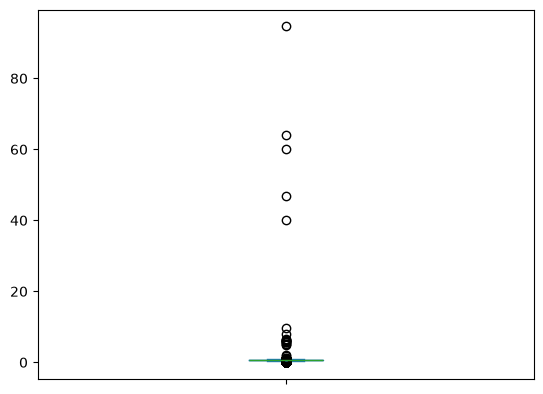

In [383]:
(df['life_sq'] / df['full_sq']).plot(kind='box')

Из графика видно, что есть множество выбросов, поэтому воспользуемся медианой

In [384]:
ratio = (df['life_sq'] / df['full_sq']).median()
print(f"median ratio: {ratio:.2f}")

df['life_sq'] = df['life_sq'].fillna(df['full_sq'] * ratio)

median ratio: 0.60


3. Какие значения имеет 25, 50 и 75 перцентили полной площади помещения

In [385]:
df['full_sq'].quantile([0.25, 0.5, 0.75])

0.25    38.0
0.50    49.0
0.75    63.0
Name: full_sq, dtype: float64

4. Посчитайте среднюю стоимость продажи помещений с общей площадью от 50 до 70 квадратных метров

In [386]:
df.loc[df['full_sq'].between(50, 70), 'price_doc'].mean()

np.float64(7243041.190994609)

5. Какая максимальная этажность здания представлена в датасете

In [387]:
df['max_floor'].max()

np.float64(117.0)

6. Выявите район с самым дорогим жильем

In [388]:
df.groupby('sub_area')['price_doc'].mean().idxmax()

'Hamovniki'

7. Посчитайте среднюю стоимость за квадратный метр жилья в Митино(Mitino)

In [389]:
mitino = df[df['sub_area'] == 'Mitino']
(mitino['price_doc'] / mitino['full_sq']).mean()

np.float64(171841.39999559196)

8. Посчитайте среднюю площадь комнаты в Бибирево

In [390]:
bibi = df[(df['sub_area'] == 'Bibirevo')]
(bibi['life_sq'] / bibi['num_room']).mean()

np.float64(16.057185628742516)

9. Проанализируйте есть ли разница в цене между квартирами на 1 и 9 этажах

In [391]:
df.groupby('floor')['price_doc'].agg(['mean','median','count']).loc[[1, 9]]

,mean,median,count
floor,,,
1.0,5.739380e+06,5569575.0,2002
9.0,6.937583e+06,6400000.0,1843


Квартиры на 9 этаже в среднем дороже примерно на 15–20 %, чем на 1 этаже

10. Найдите минимальную стоимость квартиры с жилой площадью не менее 60 квадратных метров, не менее чем 3мя комнатами и не ниже чем на 5 этаже

In [392]:
df.loc[(df['life_sq'] >= 60) & (df['num_room'] >= 3) & (df['floor'] >= 5), 'price_doc'].min()

np.int64(1000000)

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

In [393]:
import matplotlib.pyplot as plt

1. Как менялась средняя цена квартиры в Нагатинском Затоне(Nagatinski Zaton) с течением времени

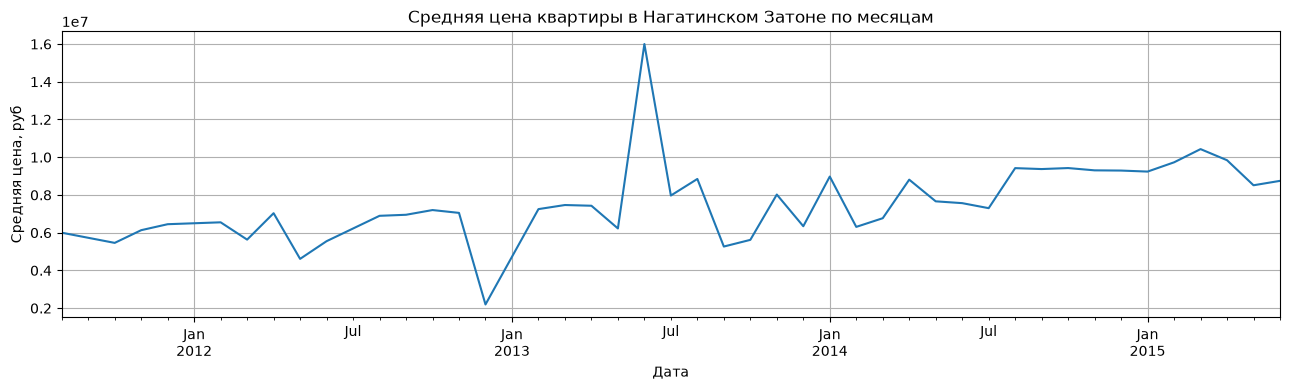

In [394]:
nz = df[df['sub_area'] == 'Nagatinskij Zaton']

plt.figure(figsize=(13, 4))
nz.groupby(nz['timestamp'].dt.to_period('M'))['price_doc'].mean().plot()
plt.title('Средняя цена квартиры в Нагатинском Затоне по месяцам')
plt.xlabel('Дата')
plt.ylabel('Средняя цена, руб')
plt.grid()
plt.tight_layout()
plt.show()

2. Постройте гистограмму распределения цен на квартиры с общей площадью более 50 кв.метров

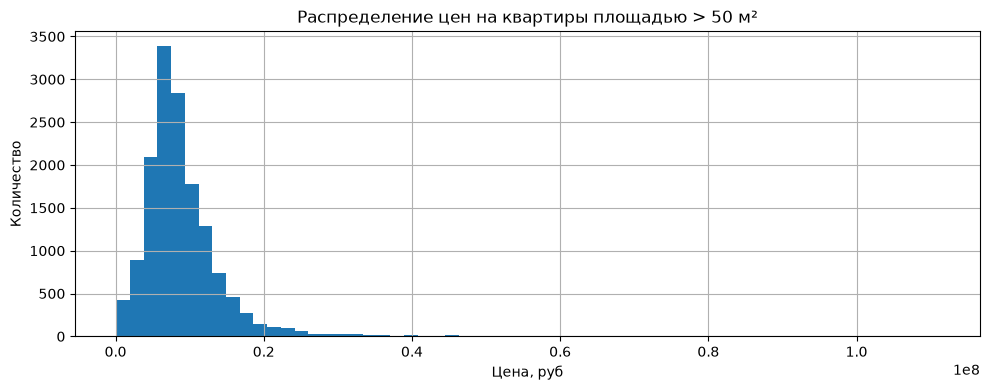

In [395]:
plt.figure(figsize=(10, 4))
plt.hist(df.loc[df['full_sq'] > 50, 'price_doc'], bins=60)
plt.title('Распределение цен на квартиры площадью > 50 м²')
plt.xlabel('Цена, руб'); plt.ylabel('Количество')
plt.grid()
plt.tight_layout()
plt.show()

3. Визуализируйте количество проданных квартир в разных районах

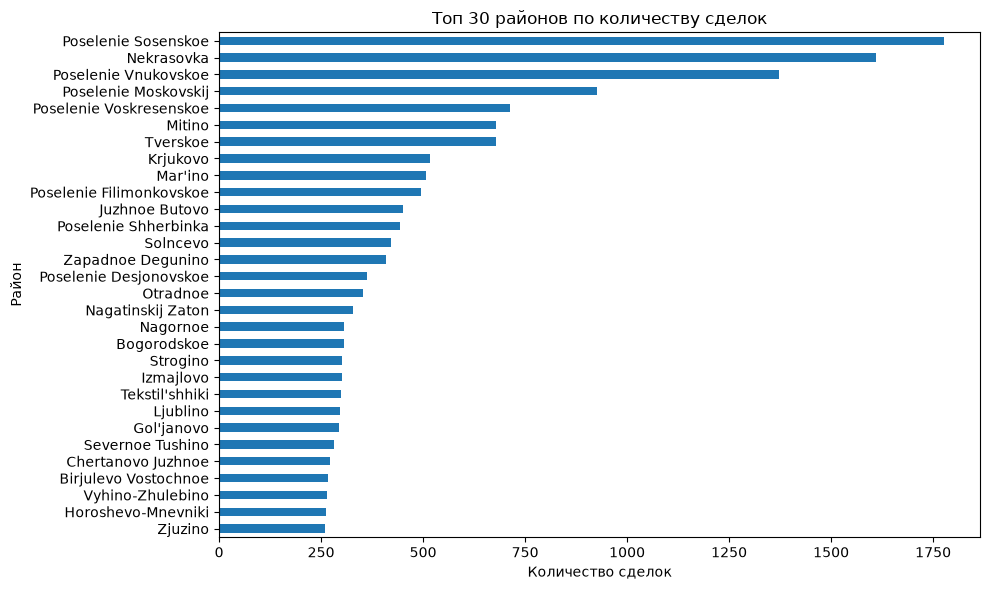

In [396]:
cnt = df['sub_area'].value_counts().head(30)

plt.figure(figsize=(10, 6))
cnt[::-1].plot(kind='barh')
plt.title('Топ 30 районов по количеству сделок')
plt.xlabel('Количество сделок')
plt.ylabel('Район')
plt.tight_layout()
plt.show()

4. Постройте box plot отображающий распределение полных площадей квартир в Басманном районе

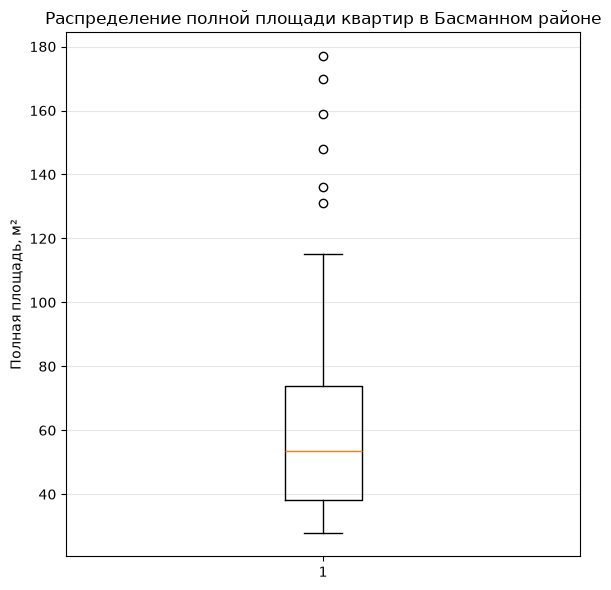

In [397]:
b = df.loc[df['sub_area'] == 'Basmannoe', 'full_sq']

plt.figure(figsize=(6, 6))
plt.boxplot(b)
plt.title('Распределение полной площади квартир в Басманном районе')
plt.ylabel('Полная площадь, м²')
plt.grid(alpha=.3, axis='y')
plt.tight_layout()
plt.show()

5. Визуализируйте зависимость средней стоимости квартир в зависимости от этажа

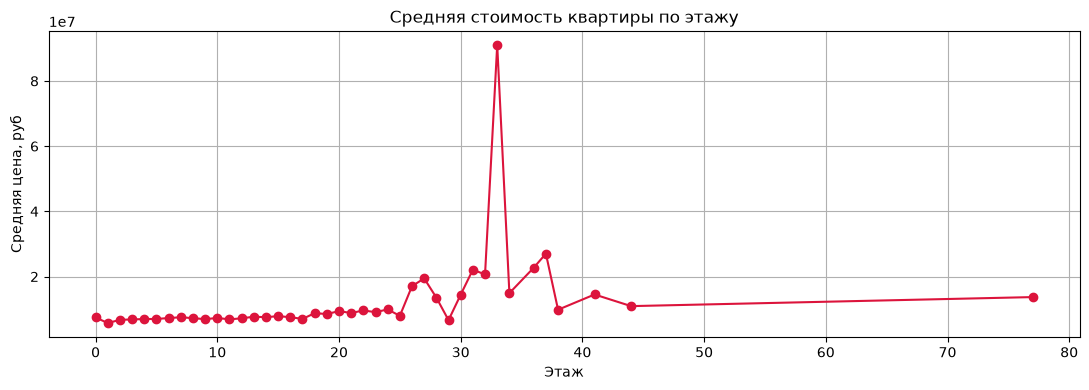

In [398]:
fl = df.groupby('floor')['price_doc'].mean()

plt.figure(figsize=(11, 4))
plt.plot(fl.index, fl.values, marker='o', color='crimson')
plt.title('Средняя стоимость квартиры по этажу')
plt.xlabel('Этаж')
plt.ylabel('Средняя цена, руб')
plt.grid()
plt.tight_layout()
plt.show()

6. Покажите как меняется средняя площадь квартир в зависимости от района

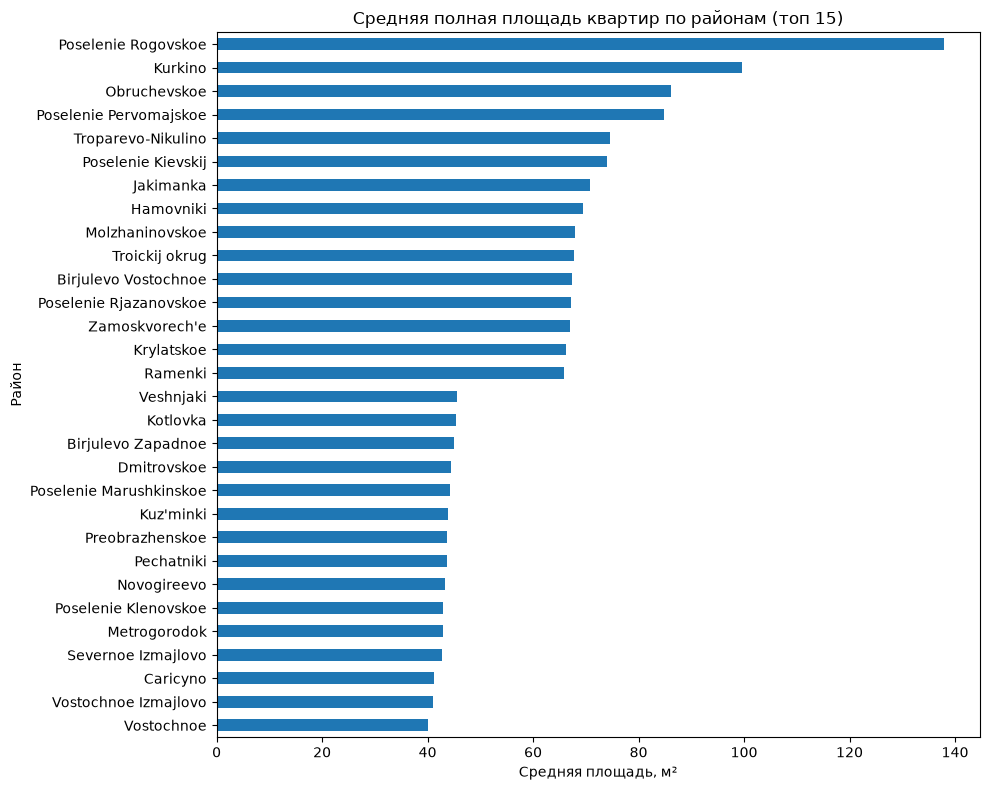

In [399]:
area = df.groupby('sub_area')['full_sq'].mean().sort_values(ascending=False)

top = pd.concat([area.head(15), area.tail(15)])

plt.figure(figsize=(10, 8))
top[::-1].plot(kind='barh')
plt.title('Средняя полная площадь квартир по районам (топ 15)')
plt.xlabel('Средняя площадь, м²'); plt.ylabel('Район')
plt.tight_layout(); plt.show()

7. Постройте график изменения медианной цены на квартиру менее 50 кв. метров за период с 2011 до 2014 года*

\* Задание на доп. балл